# ANA-063 · Aggregate statistical recovery in RUN-164

**EXP-065, RUN-164, Slurm job 2311.** This notebook audits the frozen production outputs and regenerates every analysis table and figure. It does not fit model parameters or identify empirical residue interactions.

The result is mixed. At the registered resolution, the composite has the lowest held-out joint distance for GB1, while bare GNK is closer for TrpB and CR9114-H1. The small GB1 advantage over additive-only and the CR9114-H1 difference from bare GNK are uncertain under conditional resampling. Resolution changes can reverse rankings. Latent mutation normalization survives increasing length, but observable variation collapses on uniform random backgrounds under the separate default scaling configuration.

**Run all cells in order.** Install `requirements.txt` in the selected Python kernel first. The notebook uses the collected DVC bundle and frozen submitted source, not current generator code. `analysis_tools.py` contains the auditable numerical and plotting functions. PNG and PDF figures are written to `../figures/`, and derived tables to `../tables/`.

In [1]:
from pathlib import Path
import os, sys, tempfile
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "adaptenv-ana063-mpl"))
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "labproject.yaml").exists())
analysis_dir = root / "analyses/2026-10-07_ANA-063_run-164-aggregate-thermodynamic-gnk-confirmation"
sys.path.insert(0, str(analysis_dir / "notebooks"))
import analysis_tools as a
from IPython.display import display, Image
import pandas as pd
pd.set_option("display.max_colwidth", 100)
ctx = a.load_and_audit()
print(f"Verified {len(ctx['audit']['remote_files_verified'])} remote output/log hashes and {len(ctx['audit']['frozen_source_files_verified'])} frozen source hashes.")
print(f"Independently reproduced WHT, beneficial slopes, neutral edges, and strict peaks for {ctx['audit']['empirical_cubes_recomputed']} measured cubes.")
print("All assays: 24 calibration + 24 confirmation cubes; no shared genotypes. Four calibration + eight disjoint confirmation seeds.")

Matplotlib is building the font cache; this may take a moment.


Verified 11 remote output/log hashes and 6 frozen source hashes.
Independently reproduced WHT, beneficial slopes, neutral edges, and strict peaks for 144 measured cubes.
All assays: 24 calibration + 24 confirmation cubes; no shared genotypes. Four calibration + eight disjoint confirmation seeds.


## What was tested

Each assay supplies 48 measured complete four-dimensional binary cubes, with 16 genotypes per cube. The first 24 cubes calibrate and the remaining 24 confirm; there is no shared genotype between any retained cubes within an assay. Different cubes can still share sites and alleles. Synthetic confirmation uses eight independent landscape seeds and eight cubes per seed, or 64 cubes per family and assay.

The test is **aggregate recovery on sampled subspaces**. It does not recover a whole-protein WHT, predict particular empirical interactions, or test transfer to a new protein. Synthetic models represent four active q20 sites. Their comparison with small empirical subspaces and the separate length diagnostic must not be combined into a claim of large-protein empirical validation.

Calibration-only minimum/range normalization is kept fixed, and confirmation values are not clipped. Resolution is 0.001 of the calibration fitness range. Nonfinite measurements are explicitly excluded (442 CR9114-H1 rows); missing genotypes are never imputed. Complete-cube sampling is conditional on measured completeness, so it does not remove ascertainment or assay-floor effects.

## 1. Held-out joint comparison

The registered energy distance compares ten summaries jointly: fitness SD; WHT fractions at orders ≥2 and ≥3; beneficial-mutation/background slope; anchor beneficial fraction; neutral edges; sign and reciprocal-sign epistasis; strict peaks; and accessible paths. Each feature is centred and scaled using empirical calibration cubes only, with a scale floor of 0.05. An explicit availability coordinate accompanies each feature. Undefined values remain missing in reported measurements.

The analysis independently recomputes the registered finite-sample V-statistic, including diagonal self-distances. Lower distance means closer under this particular summary/weighting scheme; zero is not a universal biological standard, and finite panels introduce bias.

Whiskers below are **2,000 paired conditional bootstrap replicates**, seed 63001. Empirical confirmation cubes are resampled, and synthetic seeds are resampled as clusters with their eight cubes retained. The same cube and seed draws are used across families. The calibration transform and selected parameters stay fixed. These intervals describe this panel's variability; they omit parameter refitting, alternative data splits, assay noise, and dependence from shared sites/alleles. They are not new acceptance gates.

,assay,family,joint_distance,bootstrap_low,bootstrap_high,calibration_distance
0,GB1,additive,1.0567,0.7768,1.5884,0.7930
1,GB1,bare_gnk,2.1039,1.7953,2.5818,2.2779
2,GB1,composite,0.9565,0.6511,1.5569,0.4207
3,TrpB,additive,2.5173,2.2219,3.0511,3.3012
4,TrpB,bare_gnk,0.1390,0.1132,0.3771,0.4090
5,TrpB,composite,0.5750,0.3942,0.9847,0.5530
6,CR9114-H1,additive,1.3222,1.1286,1.7114,0.8880
7,CR9114-H1,bare_gnk,0.2598,0.2000,0.5196,0.2386
8,CR9114-H1,composite,0.3109,0.2019,0.6218,0.1569


,assay,comparison,difference,bootstrap_low,bootstrap_high
0,GB1,composite - additive,-0.1003,-0.6926,0.5211
1,GB1,composite - bare_gnk,-1.1474,-1.5499,-0.5869
2,TrpB,composite - additive,-1.9423,-2.3061,-1.5681
3,TrpB,composite - bare_gnk,0.4360,0.2060,0.7188
4,CR9114-H1,composite - additive,-1.0113,-1.1425,-0.8714
5,CR9114-H1,composite - bare_gnk,0.0511,-0.0321,0.1724


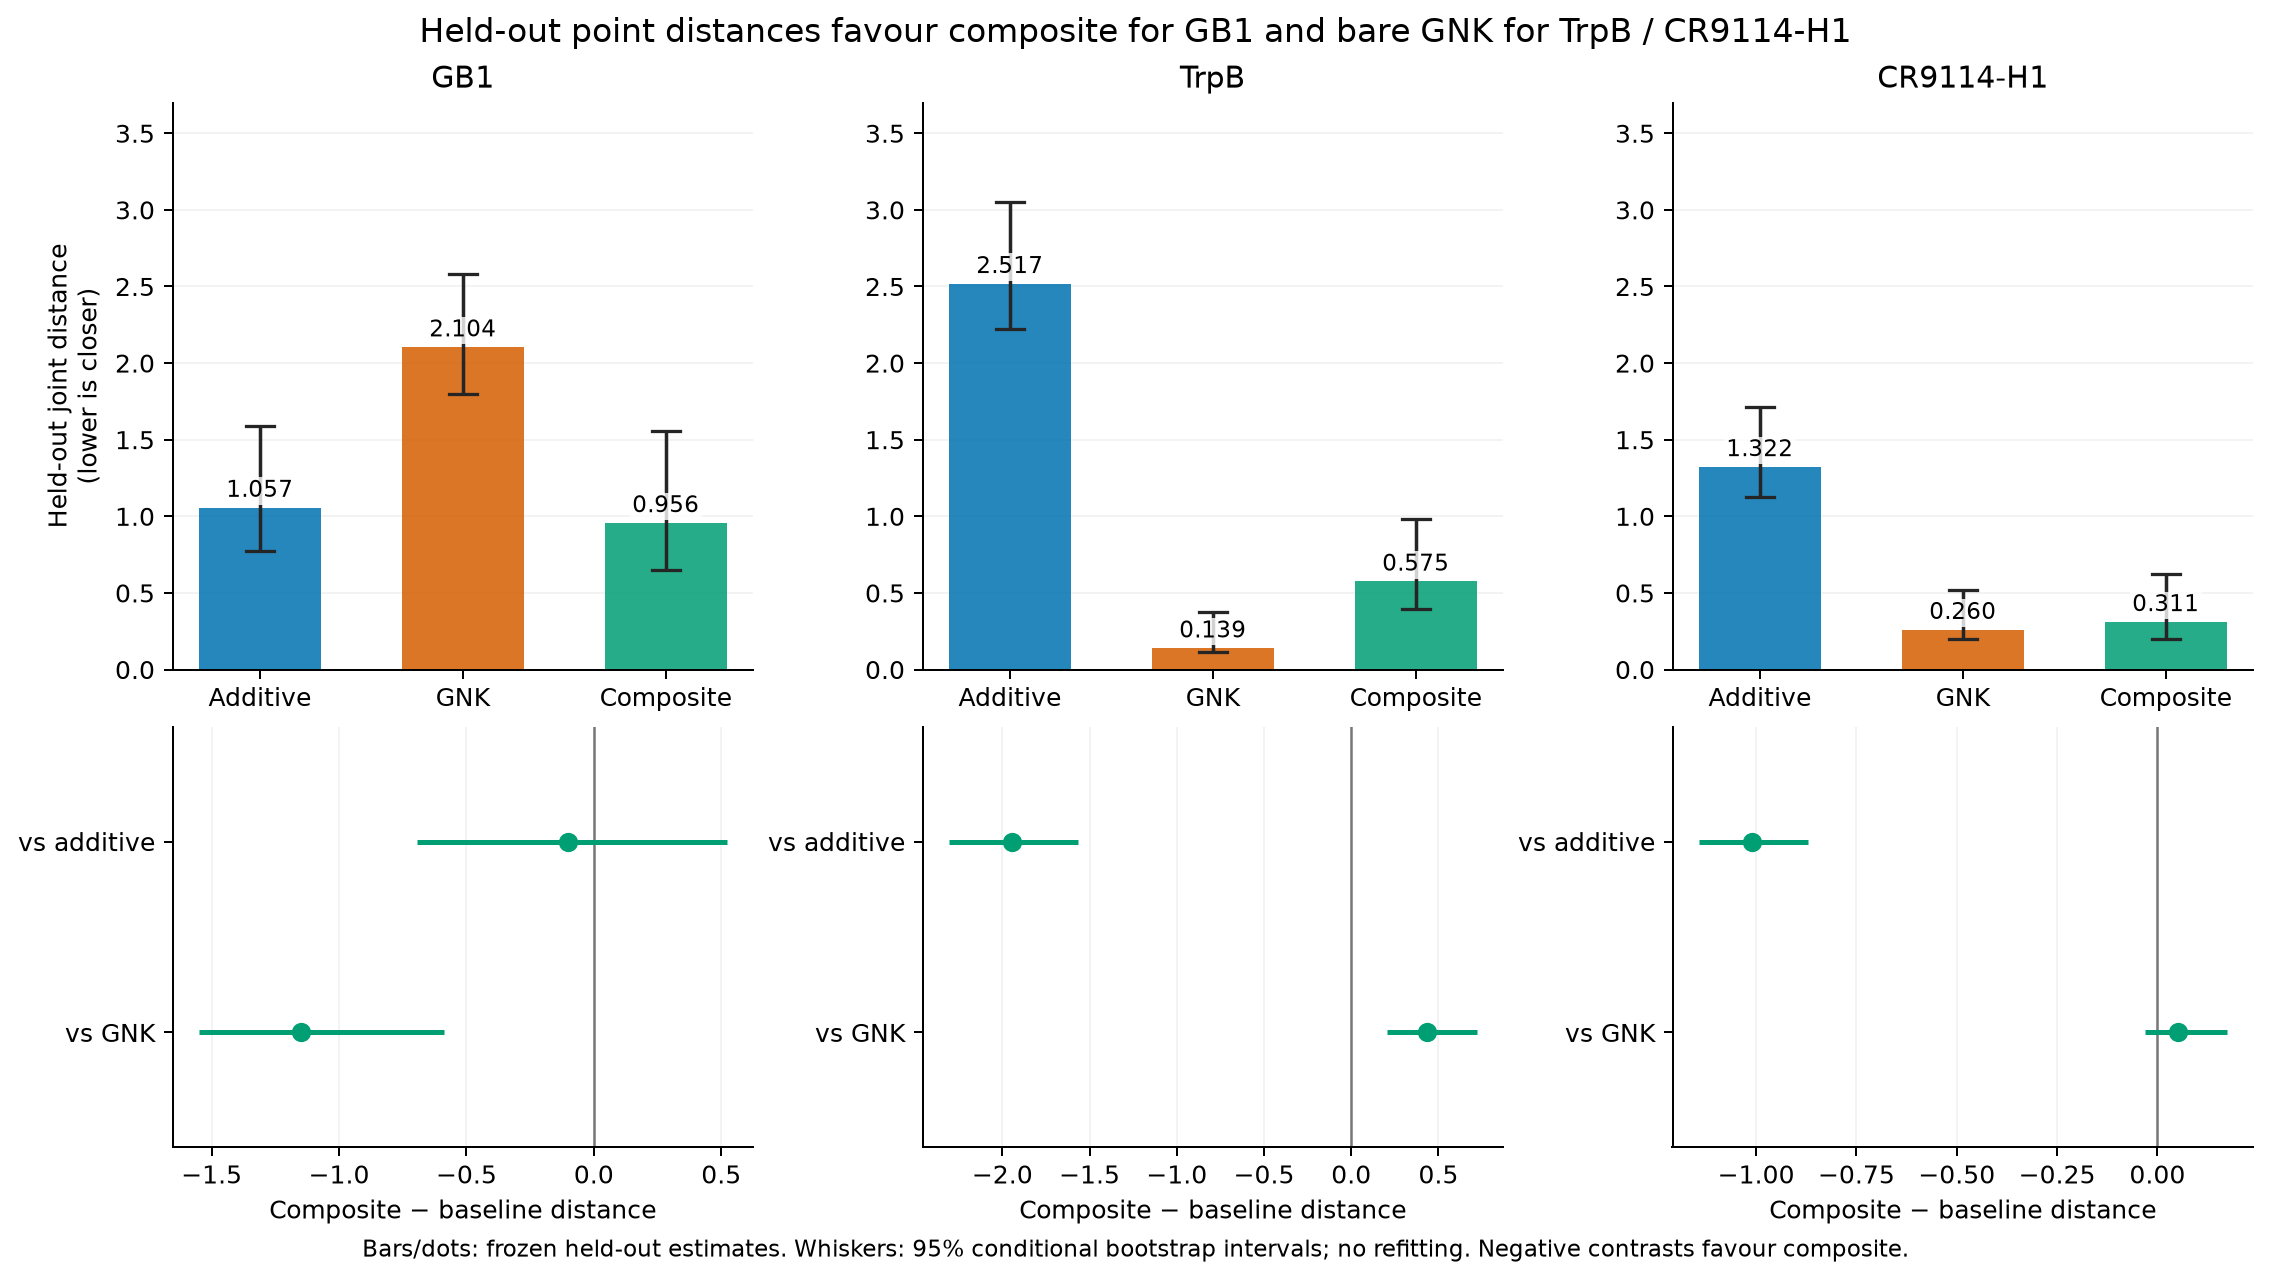

In [2]:
a.derive_comparisons(ctx)
display(ctx["comparison"][["assay", "family", "joint_distance", "bootstrap_low", "bootstrap_high", "calibration_distance"]].round(4))
display(ctx["contrasts"][["assay", "comparison", "difference", "bootstrap_low", "bootstrap_high"]].round(4))
display(Image(filename=str(a.figure_joint(ctx))))

**Figure 1.** The composite's primary point distances are 0.9565 (GB1), 0.5750 (TrpB), and 0.3109 (CR9114-H1). It improves on additive-only in all three point estimates, but beats bare GNK only on GB1. Its GB1 advantage over additive-only is −0.1003, with a conditional interval spanning zero (−0.6926 to 0.5211). On TrpB, composite minus bare GNK is +0.4360 (0.2060 to 0.7188), clearly favouring bare GNK under this resampling scheme. The corresponding CR9114-H1 contrast is +0.0511 (−0.0321 to 0.1724).

This is partial support for the proposed construction, not support for a consistent composite advantage over both baselines. Overlapping uncertainty is not proof that models are equivalent.

## 2. Which aggregate statistics remain mismatched?

A scalar distance can conceal systematic errors. Figure 2 compares held-out means using the same frozen calibration scales. Positive values mean that generated means are too high. These are descriptive standardized errors, not z-tests. Means of WHT fractions and slopes are conditional on availability; Figure 3 makes the unequal denominators visible.

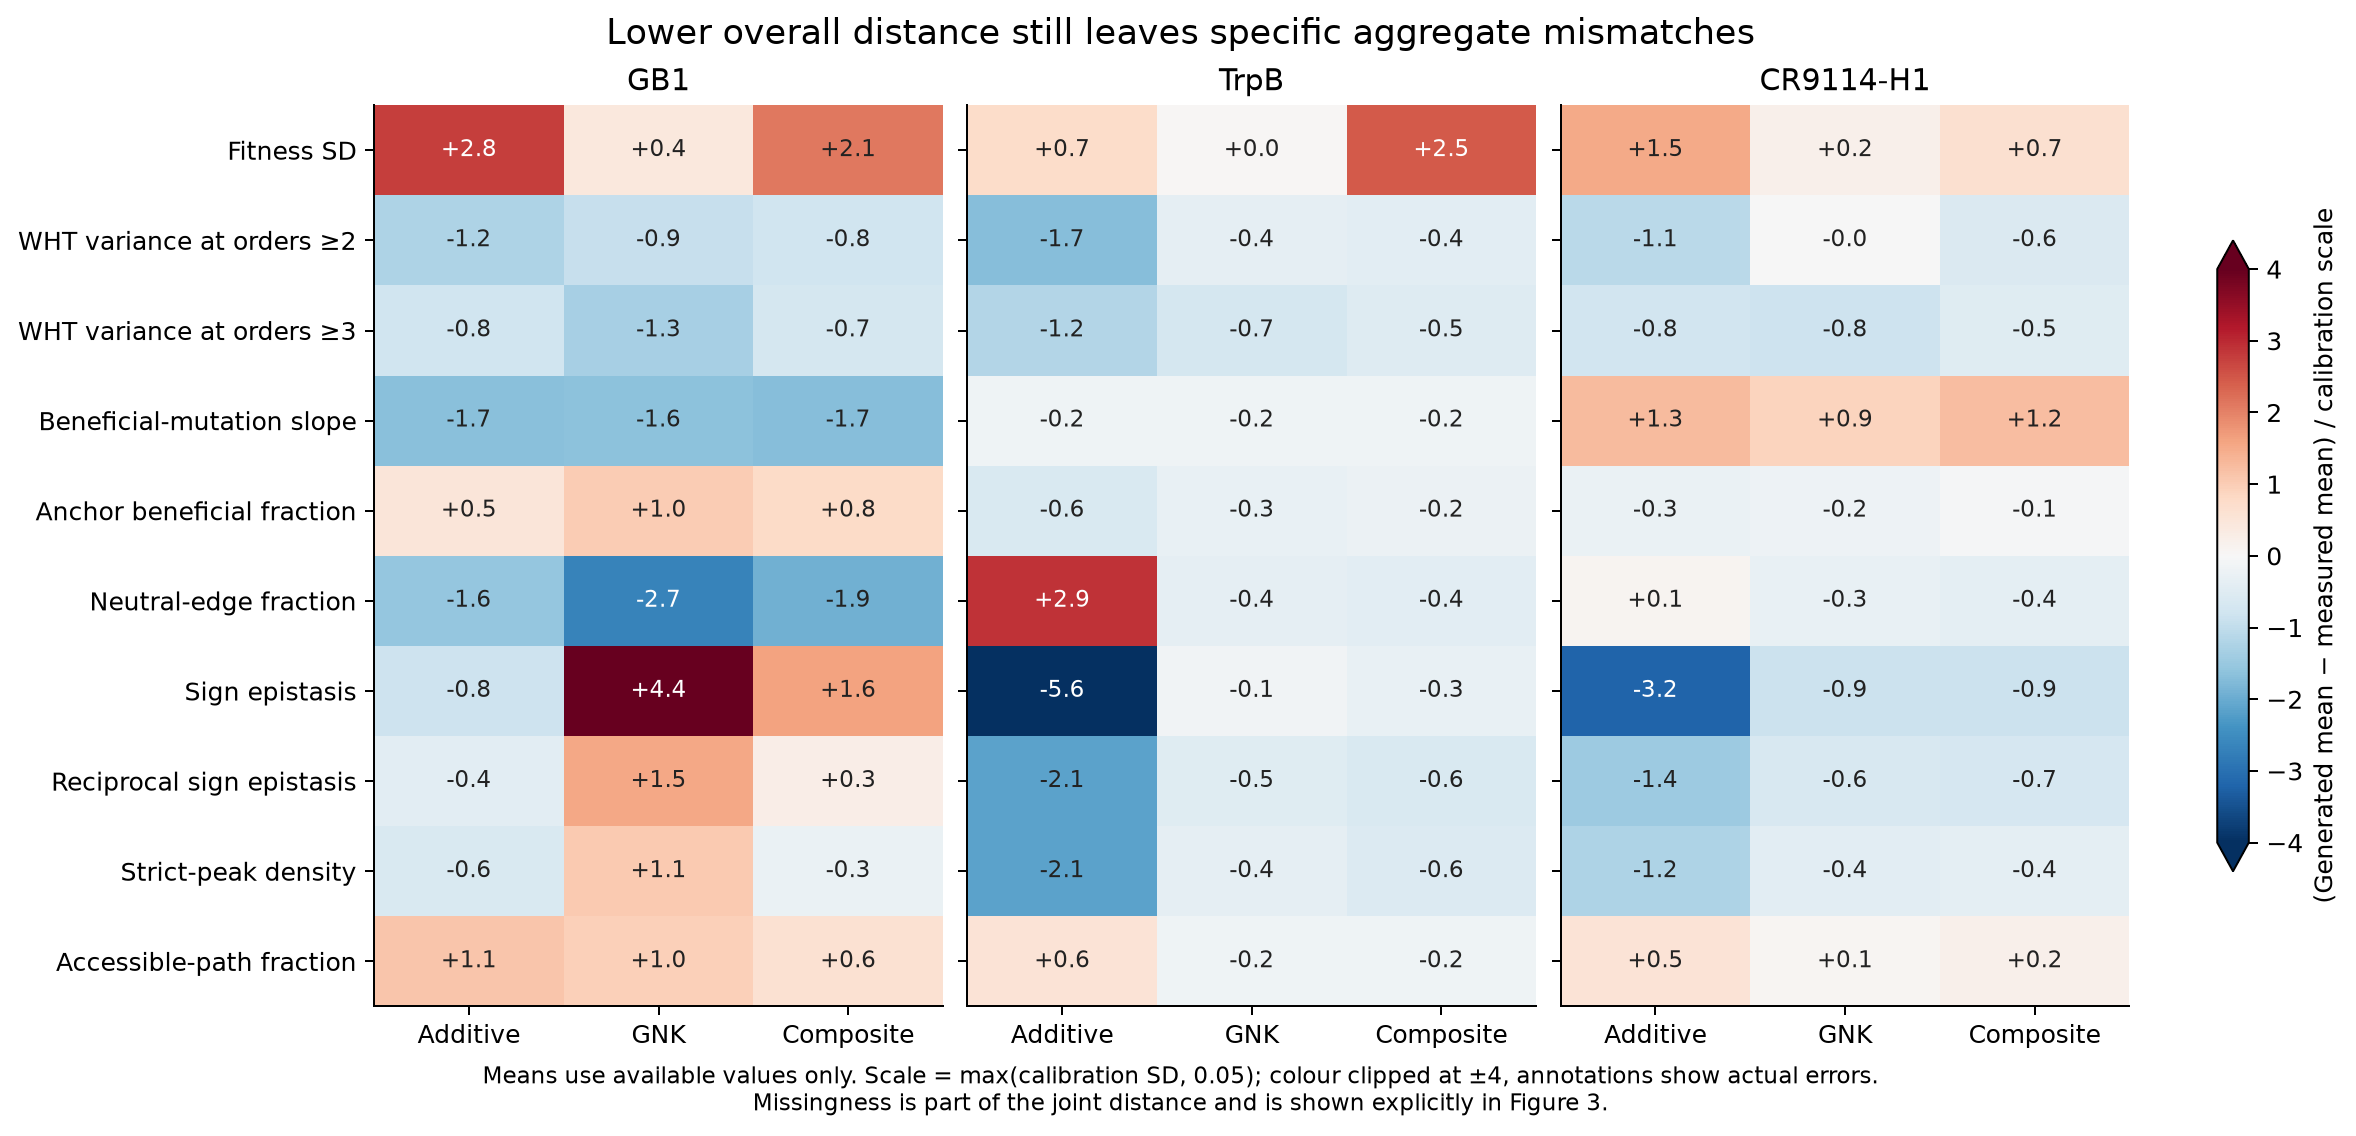

,assay,feature,empirical_mean,generated_mean,empirical_resolved_n,generated_resolved_n
20,GB1,fitness_sd,0.0095,0.1709,24,64
21,GB1,walsh_epistatic_fraction,0.5107,0.3916,14,62
22,GB1,walsh_high_order_fraction,0.1769,0.0850,14,62
23,GB1,beneficial_diminishing_returns_slope,5.4801,-0.6458,6,59
24,GB1,reference_beneficial_fraction,0.2500,0.4180,24,64
25,GB1,neutral_edge_fraction,0.5846,0.1768,24,64
26,GB1,sign_epistasis_fraction,0.0608,0.1810,24,64
27,GB1,reciprocal_sign_epistasis_fraction,0.0208,0.0339,24,64
28,GB1,local_maxima_density,0.0469,0.0332,24,64
29,GB1,accessible_path_fraction,0.0000,0.0306,24,64


In [3]:
display(Image(filename=str(a.figure_mismatch(ctx))))
display(ctx["descriptors"].query("family == 'composite'")[["assay", "feature", "empirical_mean", "generated_mean", "empirical_resolved_n", "generated_resolved_n"]].round(4))

**Figure 2.** The composite generates excessive fitness variation, particularly for GB1 and TrpB. Mean fitness SD is 0.1709 versus 0.0095 for measured GB1, and 0.2005 versus 0.0350 for TrpB (exact values are regenerated above). It underestimates high-order WHT fractions in every assay. For GB1, it also underestimates neutral-edge prevalence. A lower overall distance therefore does not establish recovery of all target statistics.

## 3. WHT and diminishing-returns distributions

WHT fractions here are background-averaged variance fractions of complete **four-site binary restrictions**, with equal weights on all 16 genotypes, on the recorded assay fitness scale. Orders ≥2 include pairwise epistasis; orders ≥3 describe higher-order terms. WHT spectra depend on the nonlinear readout and do not uniquely identify physical interaction mechanisms or topology.

The slope holds a mutation direction fixed while varying the other three bits. A mutation enters the beneficial stratum only if its mean effect across those backgrounds exceeds the resolution. Slopes are then averaged within each cube. Negative slopes describe diminishing returns for that stratum. They are not replicate-error-corrected, causal estimates, or whole-population adaptation rates. In particular, GB1's positive measured slopes cannot be confidently labelled a biological increasing-returns mechanism from these data alone.

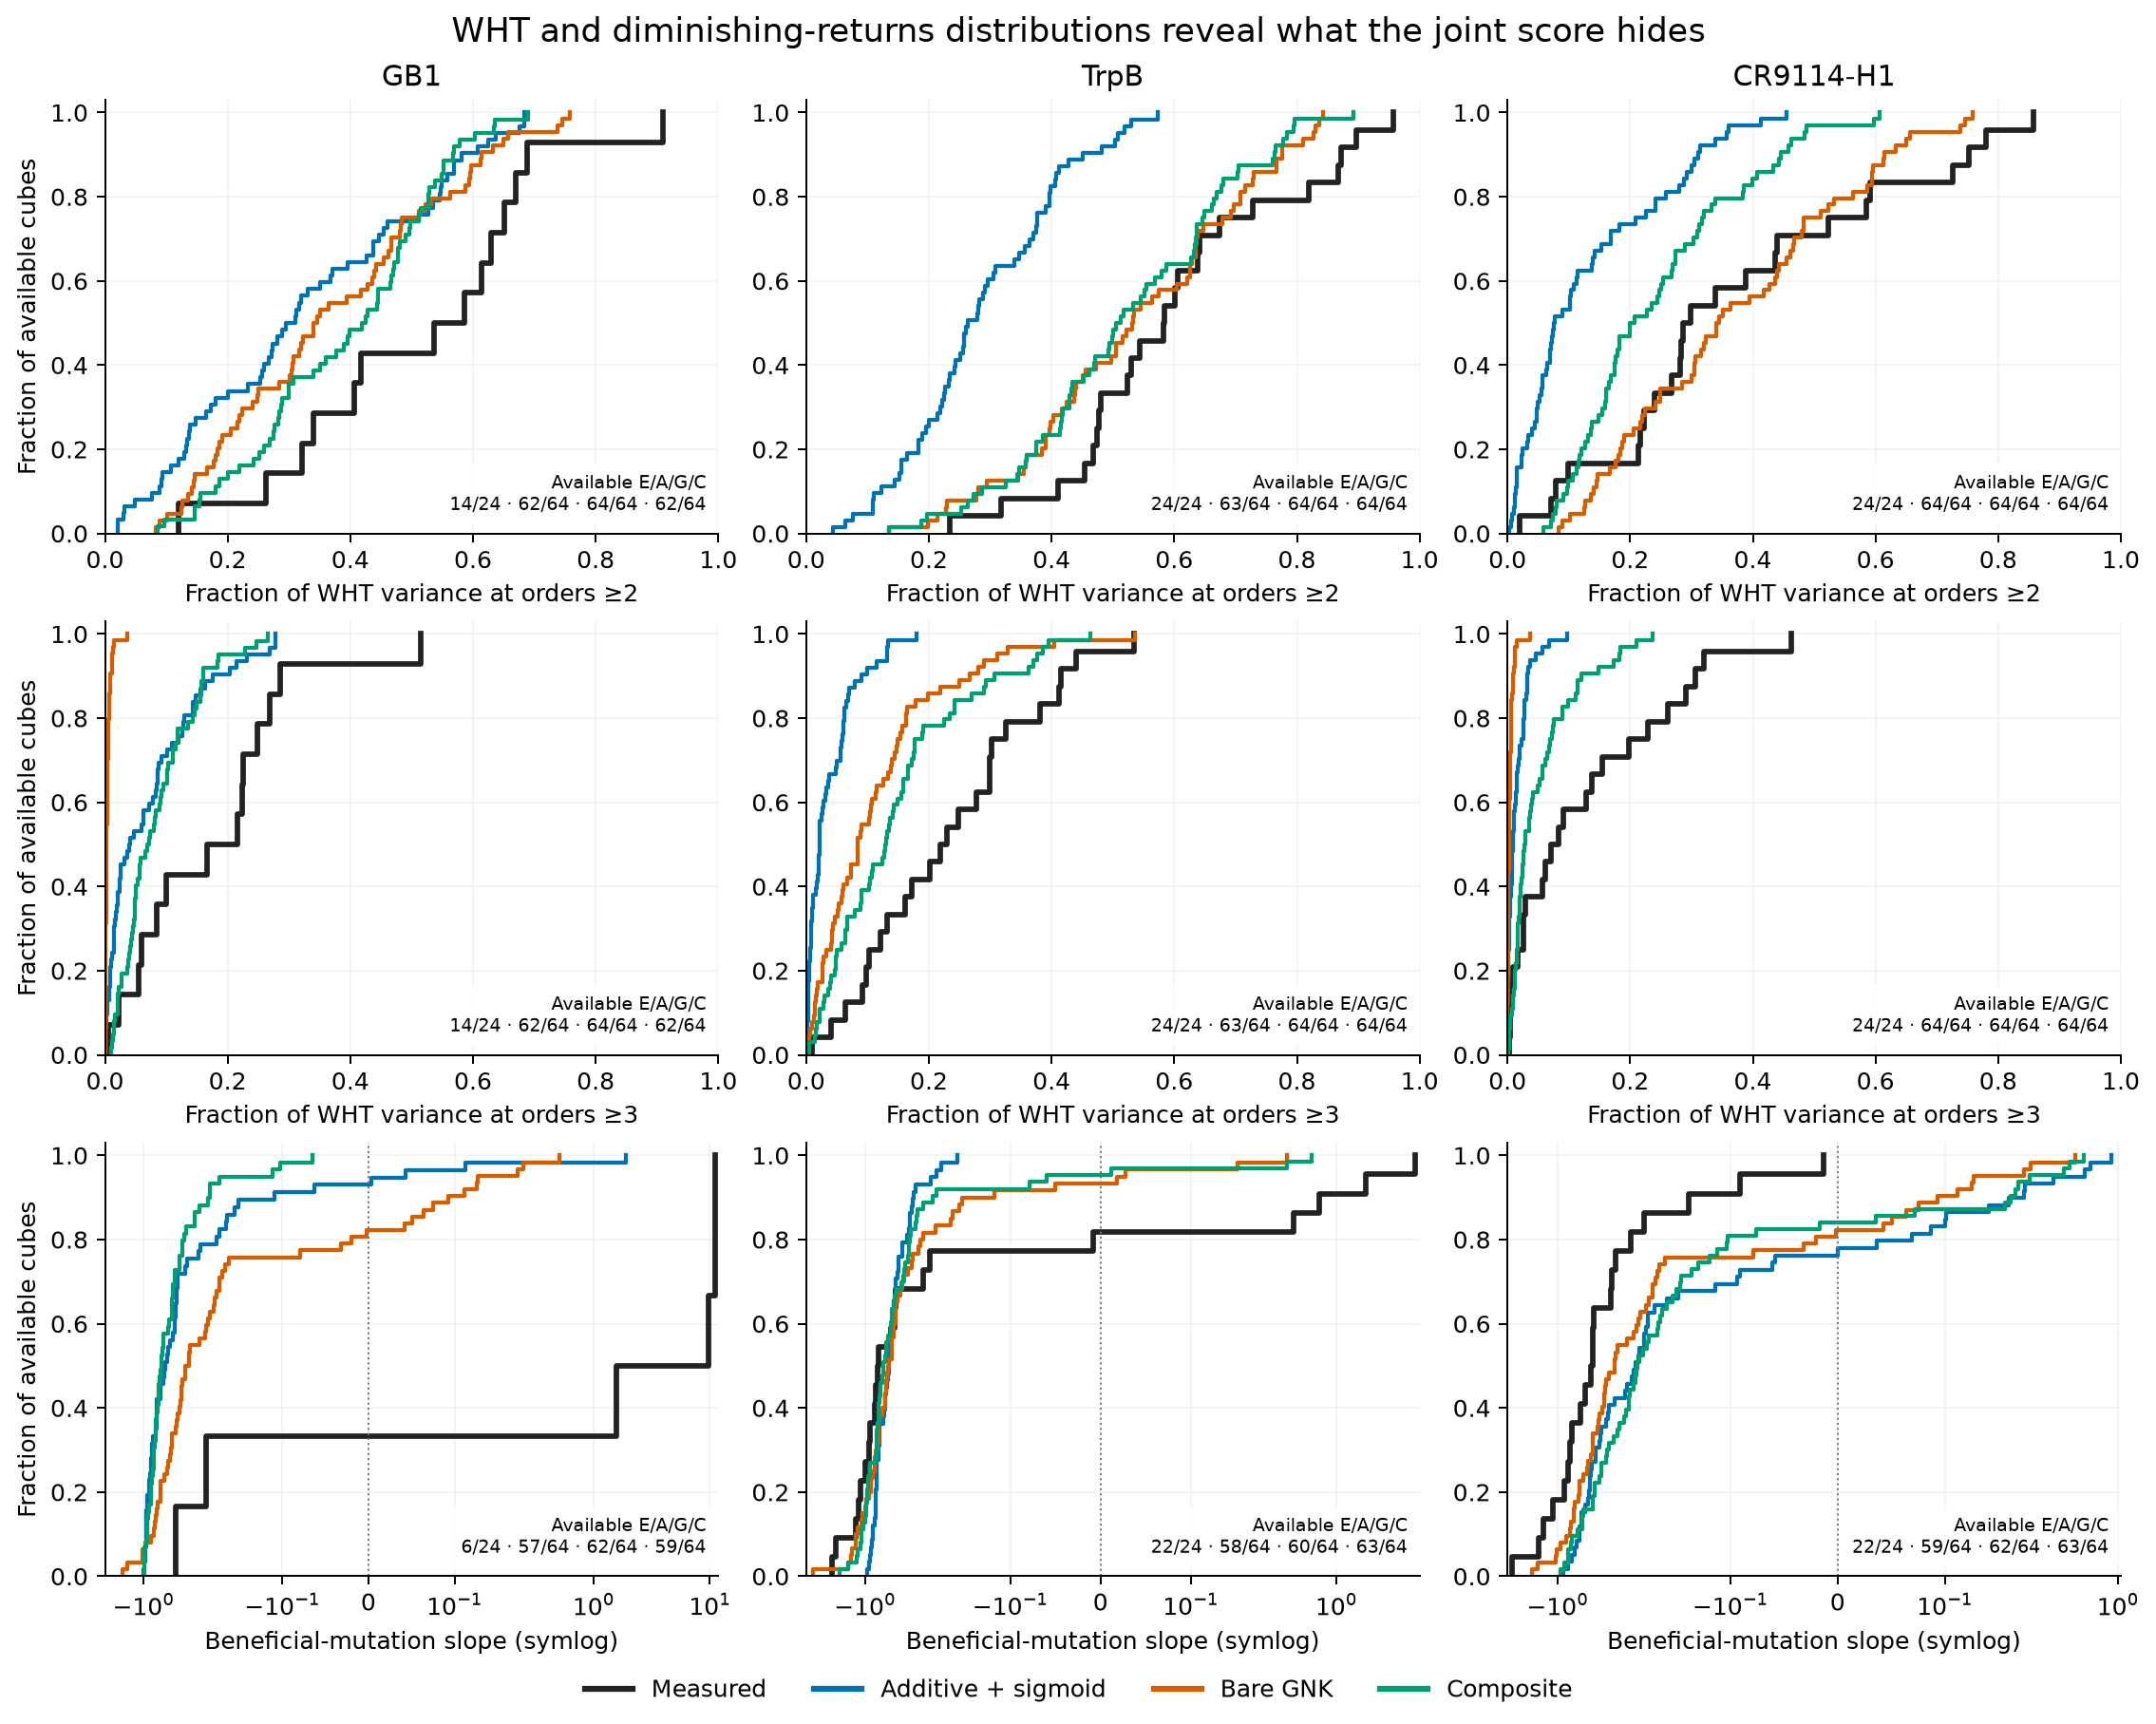

,assay,family,feature,empirical_resolved_n,generated_resolved_n,empirical_mean,generated_mean
1,GB1,additive,walsh_epistatic_fraction,14,62,0.5107,0.3242
3,GB1,additive,beneficial_diminishing_returns_slope,6,57,5.4801,-0.5614
11,GB1,bare_gnk,walsh_epistatic_fraction,14,64,0.5107,0.3711
13,GB1,bare_gnk,beneficial_diminishing_returns_slope,6,62,5.4801,-0.3982
21,GB1,composite,walsh_epistatic_fraction,14,62,0.5107,0.3916
23,GB1,composite,beneficial_diminishing_returns_slope,6,59,5.4801,-0.6458
31,TrpB,additive,walsh_epistatic_fraction,24,63,0.5991,0.2856
33,TrpB,additive,beneficial_diminishing_returns_slope,22,58,-0.3622,-0.6338
41,TrpB,bare_gnk,walsh_epistatic_fraction,24,64,0.5991,0.5341
43,TrpB,bare_gnk,beneficial_diminishing_returns_slope,22,60,-0.3622,-0.6502


In [4]:
display(Image(filename=str(a.figure_distributions(ctx))))
availability = ctx["descriptors"].query("feature in ['walsh_epistatic_fraction', 'beneficial_diminishing_returns_slope']")
display(availability[["assay", "family", "feature", "empirical_resolved_n", "generated_resolved_n", "empirical_mean", "generated_mean"]].round(4))

**Figure 3.** Empirical distributions are black; synthetic families retain the colours used throughout. ECDFs include available cube summaries only. The printed E/A/G/C counts give available/total cubes for measured, additive, GNK, and composite, respectively. Missing values are not filled with zeros.

At primary resolution, GB1 has resolved WHT fractions in 14/24 confirmation cubes and beneficial-slope summaries in only 6/24. Its available mean slope is +5.48, whereas the composite's mean is negative. TrpB and CR9114-H1 each have 22/24 available beneficial slopes. These availability differences and the unstable GB1 slope target materially limit a statement that the model recovers diminishing returns.

## 4. Resolution sensitivity

Selected parameters and the primary calibration embedding are held fixed. Only the measurement resolution changes. The three plotted settings are engineering resolutions, not estimated noise levels; equal spacing on the x-axis is categorical.

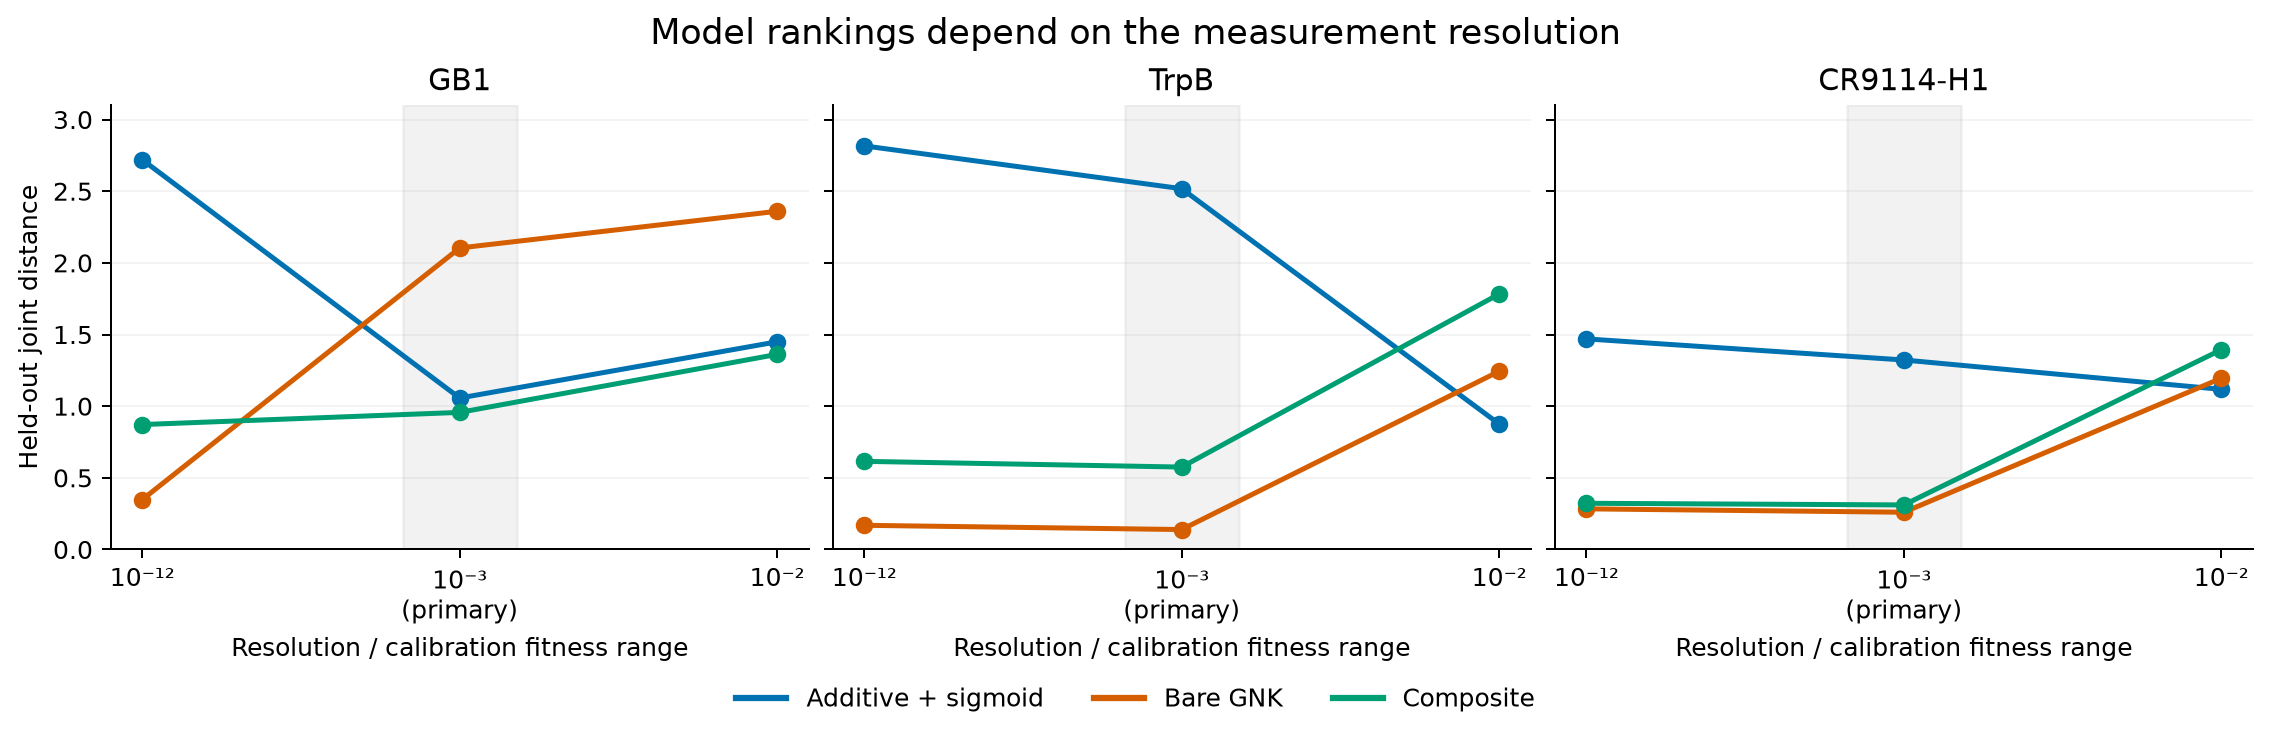

resolution           1.000000e-12  1.000000e-03  1.000000e-02
assay     family                                             
CR9114-H1 additive         1.4693        1.3222        1.1173
          bare_gnk         0.2835        0.2598        1.1944
          composite        0.3222        0.3109        1.3936
GB1       additive         2.7198        1.0567        1.4490
          bare_gnk         0.3479        2.1039        2.3598
          composite        0.8716        0.9565        1.3613
TrpB      additive         2.8161        2.5173        0.8755
          bare_gnk         0.1686        0.1390        1.2434
          composite        0.6149        0.5750        1.7825

In [5]:
display(Image(filename=str(a.figure_resolution(ctx))))
display(ctx["resolution"].assign(assay=lambda d: d.dataset.map(a.NAMES)).pivot(index=["assay", "family"], columns="resolution", values="confirmation_joint_loss").round(4))

**Figure 4.** At 10⁻¹², bare GNK is closest for all three assays. At 10⁻², additive-only becomes closest for TrpB and CR9114-H1. The apparent model ranking is therefore not robust to the treatment of small effects. The registered primary comparison is retained; the sensitivity results qualify its interpretation rather than selecting a favourable resolution afterwards.

## 5. Length scaling and saturation

The scaling panel uses the **default generator**, not each assay's fitted parameters: favourable reference rank 1, steepness 4, interaction ratio 0.25, and reference occupancy 0.99. The four-site comparison instead uses reference rank 0.5 and calibrated operating parameters. The scaling backgrounds are uniformly sampled q20 sequences, not sequences sampled around an evolved reference.

We replay only the nine frozen scaling fixtures from the submitted source, using their original seeds and mutation operator. Recorded additive and interaction RMS values, and the originally computed observable RMS, must reproduce numerically. A stable RMS calculation divides by the largest absolute effect before squaring, to distinguish squared-value underflow from exactly zero float64 mutation effects. This is a labelled post-run numerical diagnostic, not a new fit.

The generator fingerprint includes floating-point coefficients. Bitwise fingerprints can differ between the original Linux/x86 environment and this macOS/ARM analysis, even with identical source and NumPy versions. The table records this separately; numerical RMS agreement is checked at relative tolerance 10⁻¹⁰, not asserted to establish bitwise identity.

,length,seed,additive_mutation_rms,interaction_mutation_rms,observable_mutation_rms,stable_observable_rms,median_logit,zero_delta_fraction,bitwise_fingerprint_matches
0,32,65301,1.027457,0.966442,1.231494e-48,1.231494e-48,-157.224803,0.000000,False
1,32,65302,0.975738,1.031247,2.873745e-49,2.873745e-49,-159.166757,0.000000,False
2,32,65303,0.958639,1.032155,3.296810e-45,3.296810e-45,-155.325409,0.000000,False
3,128,65301,0.997999,0.999710,0.000000e+00,9.367051e-264,-675.891557,0.013672,False
4,128,65302,1.032941,0.948907,0.000000e+00,1.669070e-246,-667.493632,0.011719,False
5,128,65303,1.049783,0.995353,0.000000e+00,7.111449e-241,-668.317217,0.001953,False
6,512,65301,1.008384,1.071842,0.000000e+00,0.000000e+00,-2699.348621,1.000000,False
7,512,65302,0.933904,1.017945,0.000000e+00,0.000000e+00,-2708.088722,1.000000,False
8,512,65303,0.989810,1.045194,0.000000e+00,0.000000e+00,-2746.466574,1.000000,False


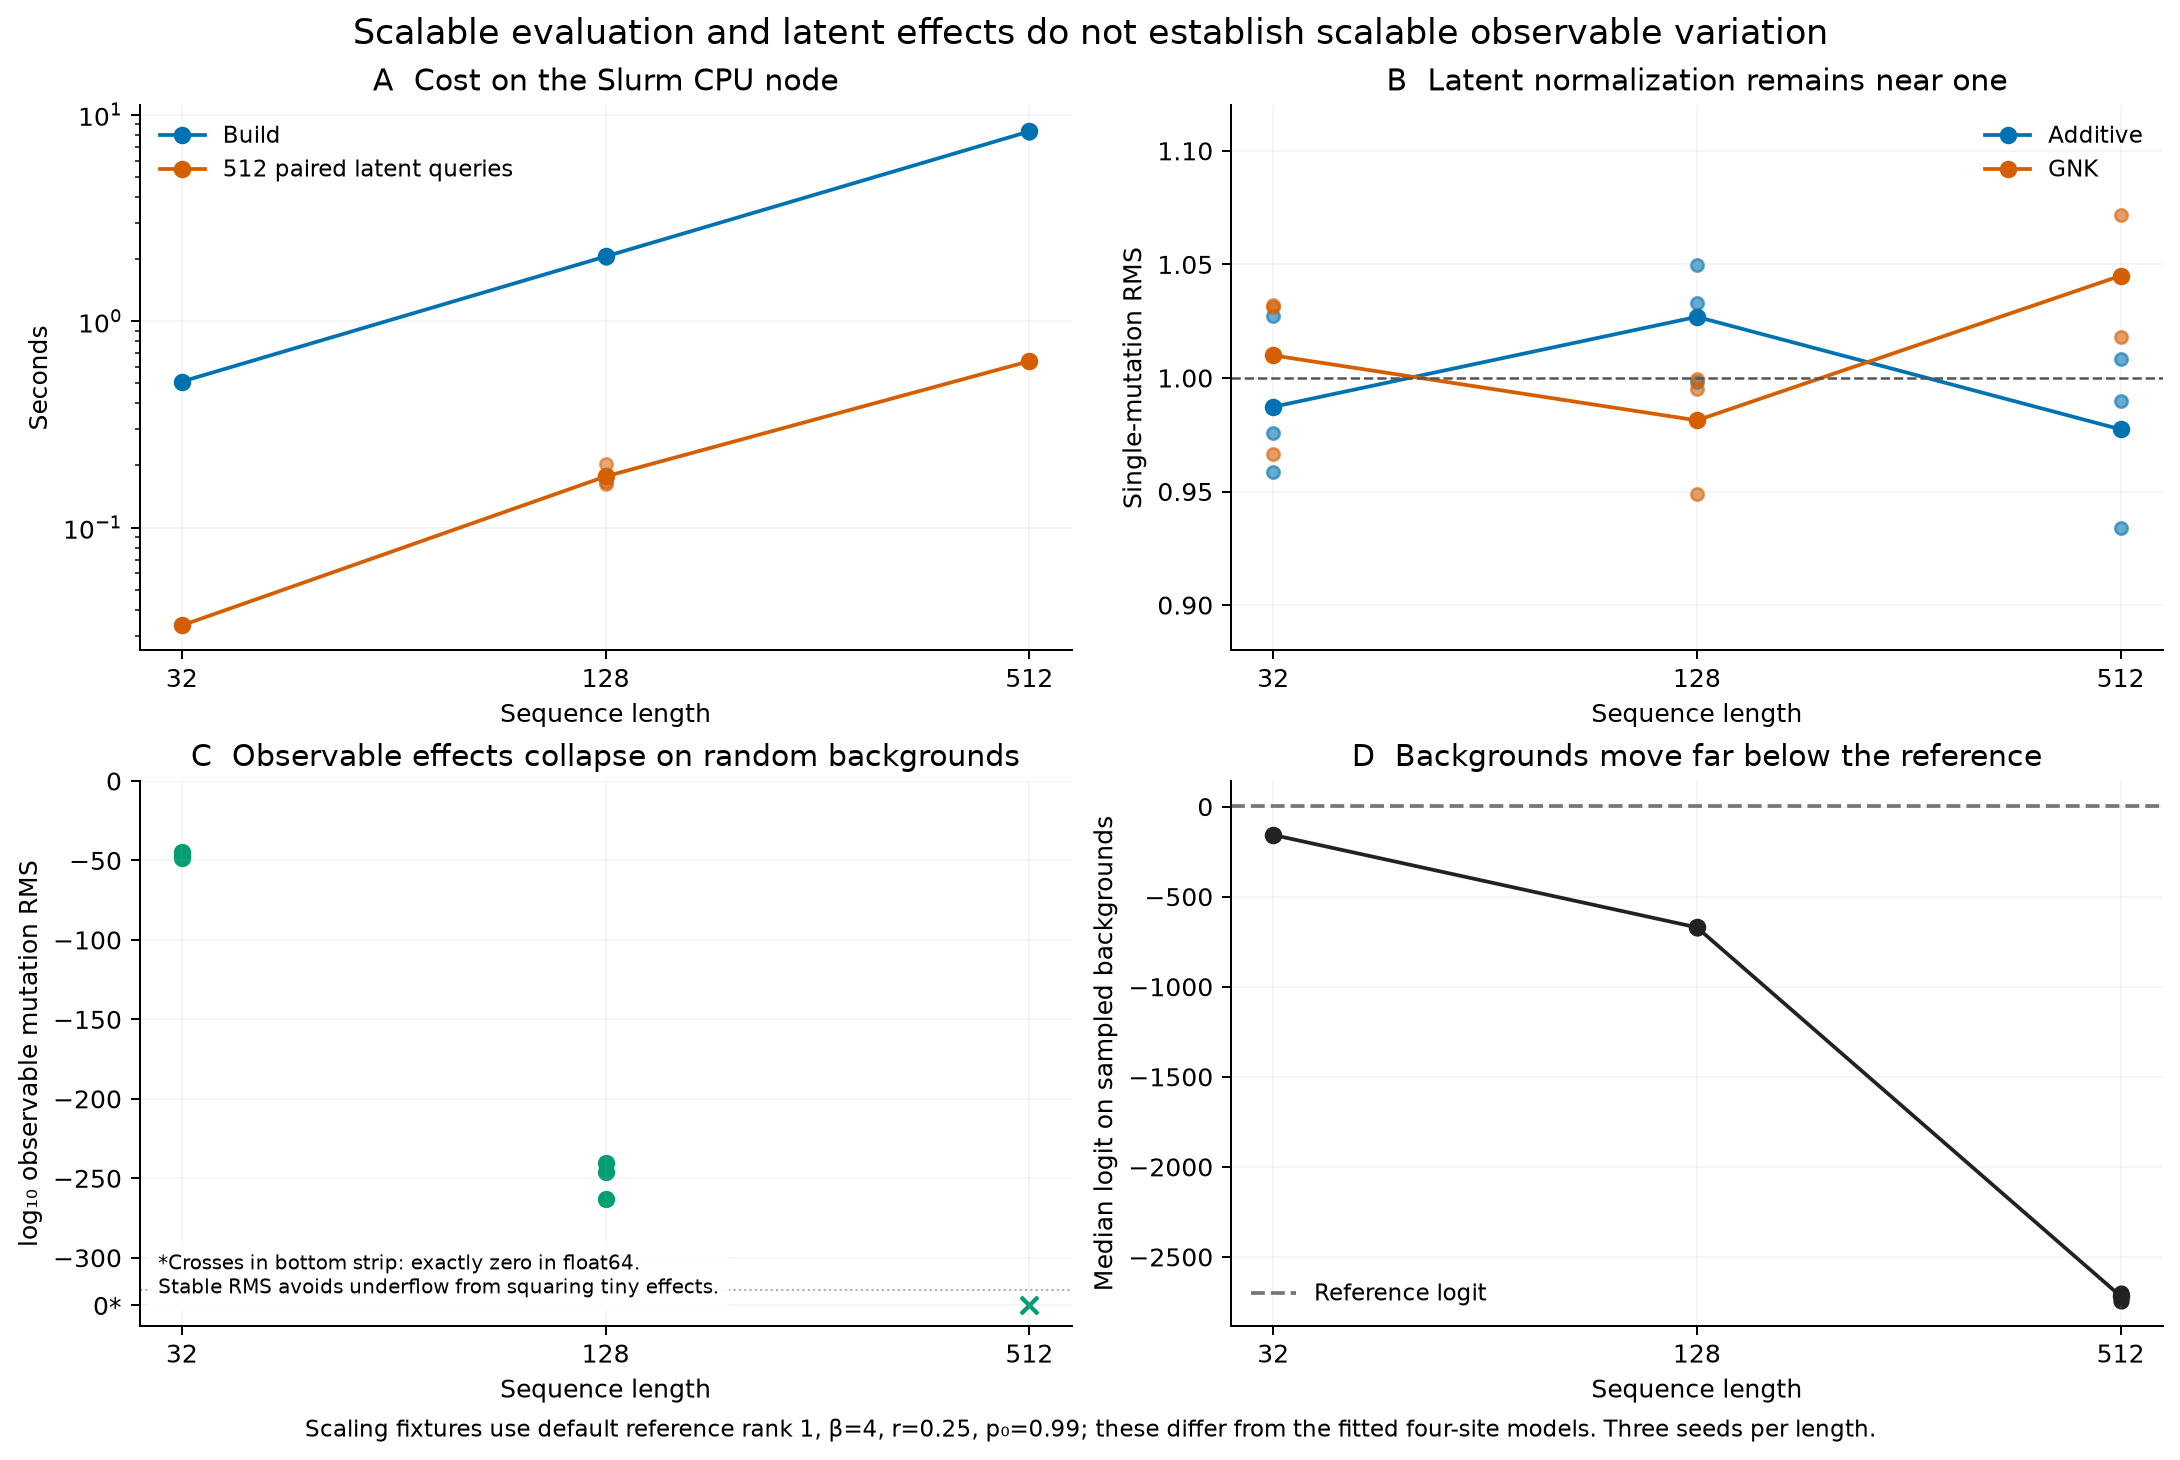

In [6]:
a.replay_scaling(ctx)
display(ctx["scaling_replay"][["length", "seed", "additive_mutation_rms", "interaction_mutation_rms", "observable_mutation_rms", "stable_observable_rms", "median_logit", "zero_delta_fraction", "bitwise_fingerprint_matches"]])
display(Image(filename=str(a.figure_scaling(ctx))))

**Figure 5.** Original run timings and mutation-normalization measurements are shown with all three seeds at each length. Latent mutation RMS stays close to one, and observed costs increase with length. Three lengths on one CPU node do not prove an asymptotic cost law.

Observable effects collapse under the default random-background configuration. Stable RMS identifies values hidden by the original squaring calculation; exact zeros are shown separately in the bottom strip, never replaced by a positive fitness effect. The increasingly negative sampled logits explain the direction of the saturation problem. Thus computational scalability and latent normalization are supported by these fixtures, while length-invariant observable variation or large-L empirical recovery is not.

## Selected parameters and reproducibility record

These are the calibration-selected grid points, not parameters chosen using confirmation performance. The TrpB composite selects the smallest tested steepness and largest tested interaction ratio. This bounds the conclusion to the tested grid; the analysis does not widen it. Bare-GNK offsets are not physically identified by the translation-invariant summaries in this objective.

In [7]:
display(ctx["comparison"][["assay", "family", "parameters"]])
metrics = a.write_metrics(ctx)
print("Analysis software:", metrics["analysis_packages"])
print("Audit, comparison, contrast, descriptor, scaling, and metrics tables written to:", a.TABLES)
print("Five figures written as PNG and PDF to:", a.FIGURES)

,assay,family,parameters
0,GB1,additive,"{""beta"": 4.0, ""family"": ""additive"", ""mixture"": 0, ""p0"": 0.99, ""ratio"": 0.0}"
1,GB1,bare_gnk,"{""family"": ""bare_gnk"", ""mixture"": 0, ""offset"": 0.0, ""scale"": 0.05}"
2,GB1,composite,"{""beta"": 2.0, ""family"": ""composite"", ""mixture"": 0, ""p0"": 0.99, ""ratio"": 1.0}"
3,TrpB,additive,"{""beta"": 2.0, ""family"": ""additive"", ""mixture"": 0, ""p0"": 0.99, ""ratio"": 0.0}"
4,TrpB,bare_gnk,"{""family"": ""bare_gnk"", ""mixture"": 1, ""offset"": 0.0, ""scale"": 0.05}"
5,TrpB,composite,"{""beta"": 0.5, ""family"": ""composite"", ""mixture"": 1, ""p0"": 0.8, ""ratio"": 4.0}"
6,CR9114-H1,additive,"{""beta"": 2.0, ""family"": ""additive"", ""mixture"": 0, ""p0"": 0.8, ""ratio"": 0.0}"
7,CR9114-H1,bare_gnk,"{""family"": ""bare_gnk"", ""mixture"": 0, ""offset"": 0.5, ""scale"": 0.1}"
8,CR9114-H1,composite,"{""beta"": 0.5, ""family"": ""composite"", ""mixture"": 1, ""p0"": 0.5, ""ratio"": 1.0}"


Analysis software: {'numpy': '2.4.4', 'pandas': '2.3.0', 'scipy': '1.17.1', 'matplotlib': '3.11.2', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
Audit, comparison, contrast, descriptor, scaling, and metrics tables written to: /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-10-07_ANA-063_run-164-aggregate-thermodynamic-gnk-confirmation/tables
Five figures written as PNG and PDF to: /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-10-07_ANA-063_run-164-aggregate-thermodynamic-gnk-confirmation/figures


## Interpretation and limits

RUN-164 supplies an executable, auditable first comparison for the narrowed aggregate goal. It does not demonstrate that a thermodynamic composite is always necessary or that empirical global statistics are generally recovered. Bare GNK provides a strong baseline, especially for TrpB; the small CR9114-H1 difference is uncertain. GB1 exposes measurement-resolution, availability, and variation mismatches despite the composite's primary point advantage.

The analysis preserves the original experiment and reports discrepancies without an inherited numerical gate. It does not infer specific empirical interactions, physical folding energies, biological causes of assay plateaus, or a universal parameter setting. It is relevant to the aggregate portion of HYP-004 and the normalization component of HYP-005, not a test of full adaptive-walk dynamics or every knob's monotonicity. No new RES or CLAIM is created by this ANA.

The scientific motivation and interpretation limits are grounded in the experiment's existing references: [Otwinowski et al. (2018)](https://doi.org/10.1073/pnas.1804015115), [Sailer & Harms (2017)](https://doi.org/10.1534/genetics.116.195214), and [Reddy & Desai (2021)](https://doi.org/10.7554/eLife.64740). Those papers motivate the model family and caution against identifying a unique mechanism from aggregate epistasis; the numerical conclusions above come from RUN-164.